# Gradient Descent from Scratch
How does a model learn? It repeats three steps: measure the error (loss), find which way is downhill (gradient), take a small step (update).
This notebook does it for the smallest possible model, a line `y = w·x + b`. Every function is written by hand and checked against NumPy.

Companion to `math-for-llm.ipynb`: that notebook shows how an LLM computes, this one shows how it learns.

## Data
A model learns from examples. Here: 50 points from a line we pretend not to know, `y = 3x + 4`, plus some noise.

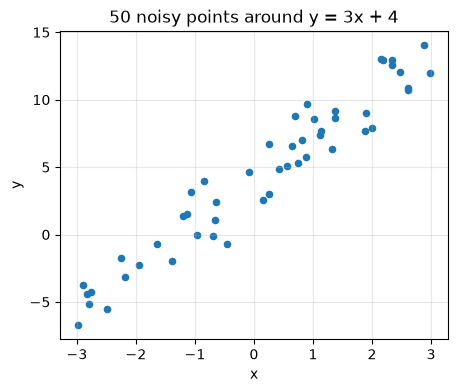

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

rng = np.random.default_rng(0)
n = 50
true_w, true_b = 3.0, 4.0

x = rng.uniform(-3, 3, size=n)
y = true_w * x + true_b + rng.normal(0, 1.5, size=n)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color="tab:blue", s=20)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("50 noisy points around y = 3x + 4")
ax.grid(alpha=0.3)
plt.show()

## Model and Loss
The model makes a prediction. The loss turns "how wrong is it?" into one number.
Mean squared error (MSE): average of the squared errors.

In [2]:
def predict(x, w, b):
    return w * x + b

def mse(y_pred, y_true):
    total = 0
    for p, t in zip(y_pred, y_true):
        total += (p - t) ** 2
    return total / len(y_true)

def loss_at(w, b):
    return mse(predict(x, w, b), y)

guess_w, guess_b = 0.5, 0.0
print(f"loss at guess (w=0.5, b=0): {loss_at(guess_w, guess_b):.2f}")
print(f"loss at truth (w=3, b=4):   {loss_at(true_w, true_b):.2f}")   # not zero because of the noise
assert np.allclose(loss_at(guess_w, guess_b), np.mean((guess_w * x + guess_b - y) ** 2))

loss at guess (w=0.5, b=0): 43.22
loss at truth (w=3, b=4):   2.29


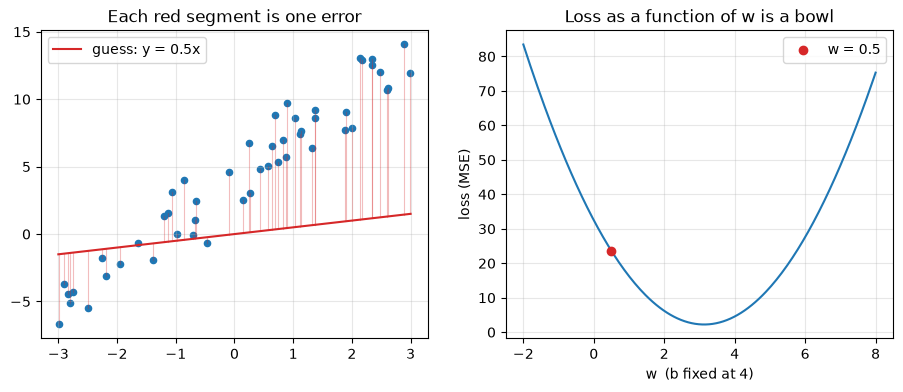

In [3]:
line_x = np.array([-3, 3])
ws = np.linspace(-2, 8, 200)
losses = [loss_at(w, true_b) for w in ws]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.scatter(x, y, color="tab:blue", s=20)
ax.plot(line_x, predict(line_x, guess_w, guess_b), color="tab:red", label="guess: y = 0.5x")
for xi, yi in zip(x, y):
    ax.plot([xi, xi], [yi, predict(xi, guess_w, guess_b)], color="tab:red", alpha=0.3, lw=0.8)
ax.set_title("Each red segment is one error")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(ws, losses, color="tab:blue")
ax.scatter([guess_w], [loss_at(guess_w, true_b)], color="tab:red", zorder=3, label="w = 0.5")
ax.set_xlabel("w  (b fixed at 4)")
ax.set_ylabel("loss (MSE)")
ax.set_title("Loss as a function of w is a bowl")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Learning = rolling down the bowl
The best `w` sits at the bottom of the bowl. Here we can draw the whole bowl, but a real model has billions of parameters,
so it can never see the landscape. It can only feel the slope where it stands. That slope is the gradient.

## Gradient
Start with the most honest definition of slope: nudge `w` a tiny bit and see how much the loss changes.
This is the numerical gradient (central difference).

In [4]:
def numerical_gradient(w, b, eps=1e-5):
    dw = (loss_at(w + eps, b) - loss_at(w - eps, b)) / (2 * eps)
    db = (loss_at(w, b + eps) - loss_at(w, b - eps)) / (2 * eps)
    return dw, db

dw, db = numerical_gradient(guess_w, guess_b)
print(f"dL/dw = {dw:.2f}, dL/db = {db:.2f}")   # both negative: increasing w and b lowers the loss

dL/dw = -17.52, dL/db = -8.90


Nudging works, but it costs two loss evaluations per parameter. With billions of parameters that is impossible.
The chain rule gives the exact slope in one pass. For a single point:

$$\hat{y} = w x + b, \qquad e = \hat{y} - y, \qquad L = e^2$$

Multiply the local derivatives, working backward from the loss:

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial w} = 2e \cdot 1 \cdot x
\qquad
\frac{\partial L}{\partial b} = 2e \cdot 1 \cdot 1$$

Average over all points:

$$\frac{\partial L}{\partial w} = \frac{2}{n}\sum_i e_i x_i \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum_i e_i$$

Going backward from the loss and multiplying local derivatives is exactly what **backpropagation** does, just through many more layers.

In [5]:
def gradient(x, y, w, b):
    dw, db = 0, 0
    for xi, yi in zip(x, y):
        error = predict(xi, w, b) - yi
        dw += 2 * error * xi
        db += 2 * error
    return dw / len(x), db / len(x)

dw, db = gradient(x, y, guess_w, guess_b)
print(f"dL/dw = {dw:.2f}, dL/db = {db:.2f}")   # same as the numerical gradient

for w, b in rng.normal(0, 5, size=(5, 2)):
    assert np.allclose(gradient(x, y, w, b), numerical_gradient(w, b), atol=1e-4)
print("analytic gradient matches numerical gradient")

dL/dw = -17.52, dL/db = -8.90
analytic gradient matches numerical gradient


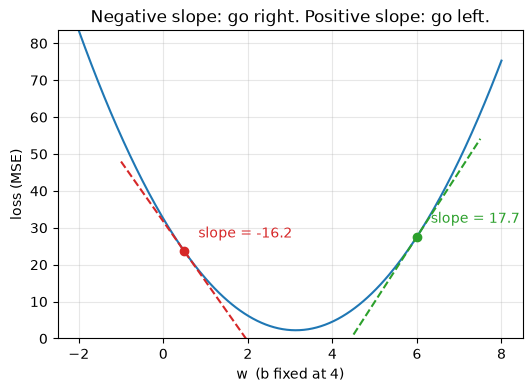

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ws, losses, color="tab:blue")
for w0, color in [(0.5, "tab:red"), (6.0, "tab:green")]:
    slope, _ = gradient(x, y, w0, true_b)
    l0 = loss_at(w0, true_b)
    t = np.linspace(w0 - 1.5, w0 + 1.5, 10)
    ax.plot(t, l0 + slope * (t - w0), color=color, ls="--")
    ax.scatter([w0], [l0], color=color, zorder=3)
    ax.annotate(f"slope = {slope:.1f}", (w0, l0), textcoords="offset points", xytext=(10, 10), color=color)
ax.set_ylim(0, max(losses))
ax.set_xlabel("w  (b fixed at 4)")
ax.set_ylabel("loss (MSE)")
ax.set_title("Negative slope: go right. Positive slope: go left.")
ax.grid(alpha=0.3)
plt.show()

## Gradient Descent
The gradient points uphill, so step the other way:

$$w \leftarrow w - \eta \cdot \frac{\partial L}{\partial w}, \qquad b \leftarrow b - \eta \cdot \frac{\partial L}{\partial b}$$

$\eta$ is the learning rate: how big each step is. Repeat until the loss stops dropping.

In [7]:
def gradient_descent(x, y, w, b, lr, steps):
    history = [(w, b, mse(predict(x, w, b), y))]
    for _ in range(steps):
        dw, db = gradient(x, y, w, b)
        w = w - lr * dw
        b = b - lr * db
        history.append((w, b, mse(predict(x, w, b), y)))
    return np.array(history)

start_w, start_b = -1.0, -4.0
history = gradient_descent(x, y, start_w, start_b, lr=0.1, steps=50)

for step in [0, 1, 5, 20, 50]:
    w, b, loss = history[step]
    print(f"step {step:2d}: w = {w:5.2f}, b = {b:5.2f}, loss = {loss:7.2f}")

step  0: w = -1.00, b = -4.00, loss =  130.00
step  1: w =  1.81, b = -2.26, loss =   49.89
step  5: w =  3.29, b =  1.47, loss =    8.71
step 20: w =  3.14, b =  3.93, loss =    2.24
step 50: w =  3.13, b =  4.03, loss =    2.24


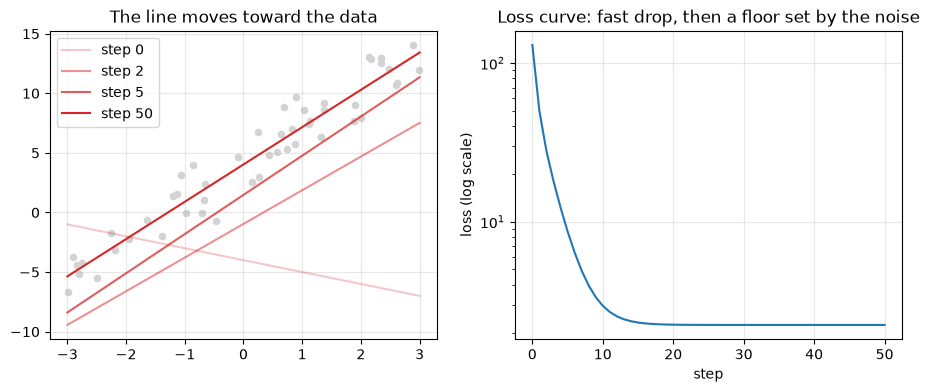

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.scatter(x, y, color="lightgray", s=20)
for step, alpha in zip([0, 2, 5, 50], [0.25, 0.5, 0.75, 1.0]):
    w, b, _ = history[step]
    ax.plot(line_x, predict(line_x, w, b), color="tab:red", alpha=alpha, label=f"step {step}")
ax.set_title("The line moves toward the data")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(history[:, 2], color="tab:blue")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("loss (log scale)")
ax.set_title("Loss curve: fast drop, then a floor set by the noise")
ax.grid(alpha=0.3)
plt.show()

## Loss Landscape
With two parameters the bowl becomes a surface. Read the contour plot like a topographic map:
each line connects points with the same loss, and the gold star is the bottom.

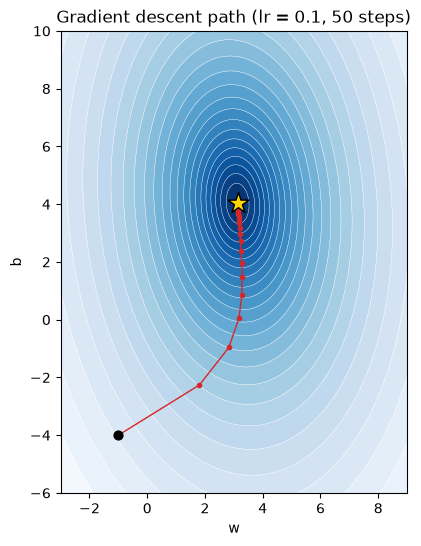

In [9]:
w_grid = np.linspace(-3, 9, 200)
b_grid = np.linspace(-6, 10, 200)
W, B = np.meshgrid(w_grid, b_grid)
loss_grid = np.mean((W[..., None] * x + B[..., None] - y) ** 2, axis=-1)   # every (w, b) at once

i, j = 50, 120
assert np.allclose(loss_grid[i, j], loss_at(W[i, j], B[i, j]))

best_w, best_b = np.polyfit(x, y, 1)   # exact minimum, used only as a reference marker

def draw_landscape(ax):
    levels = np.geomspace(loss_grid.min(), loss_grid.max(), 25)
    ax.contourf(W, B, loss_grid, levels=levels, norm=LogNorm(), cmap="Blues_r")
    ax.contour(W, B, loss_grid, levels=levels, colors="white", linewidths=0.3)
    ax.scatter(best_w, best_b, marker="*", s=250, color="gold", edgecolor="black", zorder=4)
    ax.set_xlim(w_grid[0], w_grid[-1])
    ax.set_ylim(b_grid[0], b_grid[-1])
    ax.set_aspect("equal")   # same scale on both axes, so the bowl's real shape shows
    ax.set_xlabel("w")
    ax.set_ylabel("b")

def draw_path(ax, history):
    ax.plot(history[:, 0], history[:, 1], "o-", color="tab:red", ms=3, lw=1, zorder=3)
    ax.scatter(*history[0, :2], color="black", s=40, zorder=5)

fig, ax = plt.subplots(figsize=(5, 6))
draw_landscape(ax)
draw_path(ax, history)
ax.set_title("Gradient descent path (lr = 0.1, 50 steps)")

os.makedirs("images", exist_ok=True)
fig.savefig("images/gradient-descent-path.png", dpi=150, bbox_inches="tight")
plt.show()

The path does not head straight for the star. It first slides along `w`, then creeps along `b`.
The bowl is an oval, steeper in the `w` direction (the contour lines are closer together left and right),
so the gradient is bigger there. Gradient descent only knows the local slope, not where the bottom is.

## Learning Rate
Same start, same 30 steps, four learning rates:
- **too small:** every step is tiny, it barely moves
- **just right:** reaches the bottom quickly
- **too big:** overshoots and zig-zags across the valley, but still gets there
- **way too big:** every bounce is bigger than the last one, the loss explodes (diverges)

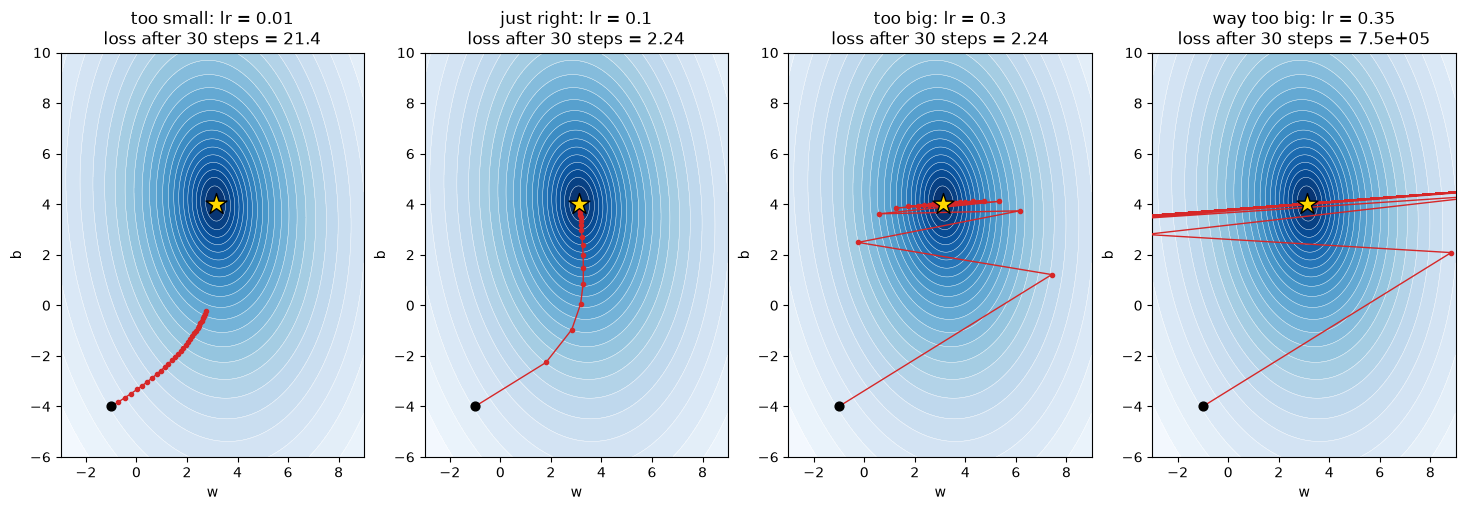

In [10]:
learning_rates = {"too small": 0.01, "just right": 0.1, "too big": 0.3, "way too big": 0.35}
runs = {name: gradient_descent(x, y, start_w, start_b, lr=lr, steps=30) for name, lr in learning_rates.items()}

fig, axes = plt.subplots(1, 4, figsize=(18, 6.5))
for ax, (name, run) in zip(axes, runs.items()):
    draw_landscape(ax)
    draw_path(ax, run)
    ax.set_title(f"{name}: lr = {learning_rates[name]}\nloss after 30 steps = {run[-1, 2]:.3g}")
fig.savefig("images/learning-rates.png", dpi=150, bbox_inches="tight")
plt.show()

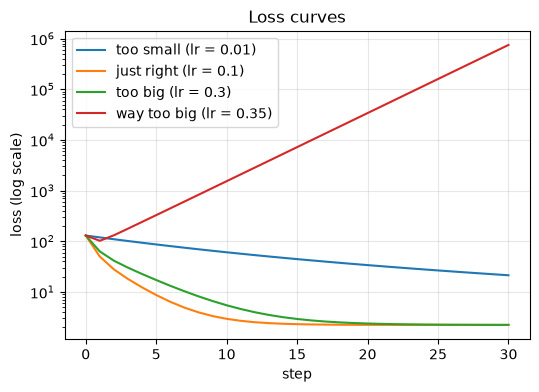

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, run in runs.items():
    ax.plot(run[:, 2], label=f"{name} (lr = {learning_rates[name]})")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("loss (log scale)")
ax.set_title("Loss curves")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

There is a cliff between 0.3 and 0.35. Past a critical learning rate (about 0.32 here, set by how steep the bowl is),
training does not just get slower, it blows up. Bigger is not always faster.

## Animation
The same path as a GIF, saved for the README.

In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter

fig, ax = plt.subplots(figsize=(4, 5))
draw_landscape(ax)
ax.scatter(*history[0, :2], color="black", s=40, zorder=5)
path, = ax.plot([], [], "o-", color="tab:red", ms=3, lw=1, zorder=3)

def update(frame):
    path.set_data(history[:frame + 1, 0], history[:frame + 1, 1])
    ax.set_title(f"step {frame}: loss = {history[frame, 2]:.2f}")
    return path,

frames = list(range(26)) + [25] * 12   # after step 25 the path barely moves, so hold that frame
anim = FuncAnimation(fig, update, frames=frames)
anim.save("images/gradient-descent.gif", writer=PillowWriter(fps=8), dpi=80)
plt.close(fig)
print("saved images/gradient-descent.gif")

saved images/gradient-descent.gif


## Check against the exact answer
Linear regression has a closed-form solution (least squares), so we can check that gradient descent found the real bottom.

In [13]:
final_w, final_b, final_loss = history[-1]
print(f"gradient descent: w = {final_w:.4f}, b = {final_b:.4f}")
print(f"least squares:    w = {best_w:.4f}, b = {best_b:.4f}")
assert np.allclose([final_w, final_b], [best_w, best_b], atol=1e-3)

gradient descent: w = 3.1309, b = 4.0286
least squares:    w = 3.1308, b = 4.0287


Both find `w ≈ 3.13, b ≈ 4.03`, not exactly `3` and `4`. With noisy data, the best line for these 50 points is not quite the true line.

### Why this matters for LLMs
Training an LLM is this same loop: predict, measure the loss, follow the gradient downhill, repeat.
What changes is the scale:

| This notebook | Training an LLM |
|---|---|
| 2 parameters (`w`, `b`) | Billions of parameters: the weight matrices from `math-for-llm.ipynb` |
| MSE loss | Cross-entropy: `-log` of the probability softmax gave to the correct next token |
| Gradient derived by hand with the chain rule | Backpropagation: the same chain rule, automated by autograd (PyTorch) |
| All 50 points every step | Mini-batches of tokens (stochastic gradient descent) |
| One fixed learning rate | Adam optimizer plus a learning rate schedule (warmup, then decay) |

The learning rate plots are what real training runs look like. A loss curve that explodes means the learning rate is too high,
one that barely moves means it is too low. Fine-tuning (including LoRA) runs the exact same loop, LoRA just limits which parameters get updated.

## Summary: how a model learns
The **loss** turns "how wrong is the model?" into one number, and as a function of the parameters it forms a bowl.
The **gradient** is the slope of that bowl at the current point. The **chain rule** computes it exactly by multiplying
local derivatives backward from the loss, which is what backpropagation does in every neural network.
**Gradient descent** steps against the gradient, again and again. The **learning rate** decides whether it crawls,
converges, or blows up.